# ANA500 Micro-Project 4: Adult Income Deep Learning Classification

**Student:** Valentin Diaconu  
**Course:** ANA500  
**Scope:** Data Science Process Steps 1-5: Acquire, Prepare, Analyze, Report, and Act

This project extends the Adult Income portfolio analysis with deep learning. It compares a majority baseline, logistic regression, a dense multilayer perceptron (MLP), and an LSTM network for predicting whether reported annual income exceeds $50,000.

## AI Use Disclosure & Academic Integrity Compliance

OpenAI ChatGPT assisted with project organization, code drafting and debugging, and phrasing refinement. The author reviewed and executed the code and remains responsible for the analysis. All numerical results and charts come from the executed Adult Income analysis. AI-generated text does not replace the dataset, model output, or the author's academic responsibility. Assisted passages may be cited as **(OpenAI, 2026)**.

## Important methodological disclosure

The Adult Income dataset is cross-sectional. It contains no timestamps and no natural sequence of observations. Therefore, this project is a **deep learning classification analysis rather than a time-series analysis**.

For the LSTM demonstration, the one-hot encoded predictor vector is reshaped into an analyst-defined feature sequence. This allows the recurrent architecture to run, but the sequence positions do not represent time. LSTM performance must therefore be interpreted only as an architecture comparison, not evidence of temporal learning. This limitation directly affects whether the project fully satisfies a time-series requirement.

## Problem statement and hypothesis

**Problem statement:** Can deep neural networks use demographic, educational, and employment characteristics to classify whether an adult reports annual income above $50,000?

**Hypothesis:** The MLP and LSTM will outperform the majority baseline because nonlinear layers can represent interactions among the available predictors. The LSTM may not outperform the MLP because the encoded predictors have no natural temporal order. (OpenAI, 2026)

## Step 1: Acquire

The analysis uses the Adult Income dataset derived from 1994 U.S. Census data. The code checks the student's course-data folder and local project locations before falling back to the original UCI source.

In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL']='2'
os.environ['TF_DETERMINISTIC_OPS']='1'
from pathlib import Path
import random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks, regularizers
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay
from sklearn.utils.class_weight import compute_class_weight

RANDOM_STATE=42
random.seed(RANDOM_STATE); np.random.seed(RANDOM_STATE); tf.random.set_seed(RANDOM_STATE)
tf.config.threading.set_intra_op_parallelism_threads(1)
tf.config.threading.set_inter_op_parallelism_threads(1)
sns.set_theme(style='whitegrid',context='notebook')
FIGURE_DIR=Path('/workspace/scratch/5c771a5a372b/output/mp4_adult/figures'); FIGURE_DIR.mkdir(parents=True,exist_ok=True)

MAC_PATH=Path('/Users/valentindiaconu/Desktop/NU Data Sciense/ANA500/datasets/adult income.csv')
LOCAL=[Path('adult income.csv'),Path('../adult income.csv'),Path('../../upload/adult income.csv'),Path('/workspace/scratch/5c771a5a372b/upload/adult income.csv')]
COLS=['age','workclass','fnlwgt','education','education-num','marital-status','occupation','relationship','race','sex','capital-gain','capital-loss','hours-per-week','native-country','income']
if MAC_PATH.exists(): source=MAC_PATH
elif next((p for p in LOCAL if p.exists()),None) is not None: source=next(p for p in LOCAL if p.exists())
else: source='https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data'
adult=pd.read_csv(source,skipinitialspace=True) if not str(source).startswith('http') else pd.read_csv(source,names=COLS,skipinitialspace=True)
if adult.shape[1]==15 and list(adult.columns)!=COLS: adult.columns=COLS
print('TensorFlow:',tf.__version__); print('Source:',source); print('Shape:',adult.shape)
adult.head()

TensorFlow: 2.21.0
Source: /workspace/scratch/5c771a5a372b/upload/adult income.csv
Shape: (32561, 15)
Out[0]: 
   age         workclass  fnlwgt  ... hours-per-week  native-country income
0   39         State-gov   77516  ...             40   United-States  <=50K
1   50  Self-emp-not-inc   83311  ...             13   United-States  <=50K
2   38           Private  215646  ...             40   United-States  <=50K
3   53           Private  234721  ...             40   United-States  <=50K
4   28           Private  338409  ...             40            Cuba  <=50K

[5 rows x 15 columns]


## Step 2: Prepare

Preparation follows the earlier micro-projects. The code trims text safely across Pandas versions, converts question-mark codes into explicit `Unknown` categories, removes exact duplicates, and creates a binary target. It retains plausible extreme values because they may contain predictive information.

The project uses stratified training, validation, and test partitions. The preprocessing pipeline fits only on training data. Numerical variables receive median imputation and standardization; categorical variables receive most-frequent imputation and one-hot encoding.

In [2]:
text_columns=adult.columns[adult.dtypes.map(pd.api.types.is_string_dtype)]
clean=adult.copy()
clean[text_columns]=clean[text_columns].apply(lambda s:s.astype('string').str.strip().replace('?',pd.NA)).fillna('Unknown')
duplicates=int(clean.duplicated().sum()); clean=clean.drop_duplicates().reset_index(drop=True)
clean['income']=clean['income'].str.replace('.','',regex=False)
clean['income_binary']=(clean['income']=='>50K').astype('int8')
pd.Series({'original_rows':len(adult),'duplicates_removed':duplicates,'prepared_rows':len(clean),'unknown_workclass':int((clean.workclass=='Unknown').sum()),'unknown_occupation':int((clean.occupation=='Unknown').sum()),'remaining_nulls':int(clean.isna().sum().sum()),'positive_class_percent':clean.income_binary.mean()*100}).round(2)

Out[0]: 
original_rows             32561.00
duplicates_removed           24.00
prepared_rows             32537.00
unknown_workclass          1836.00
unknown_occupation         1843.00
remaining_nulls               0.00
positive_class_percent       24.09
dtype: float64


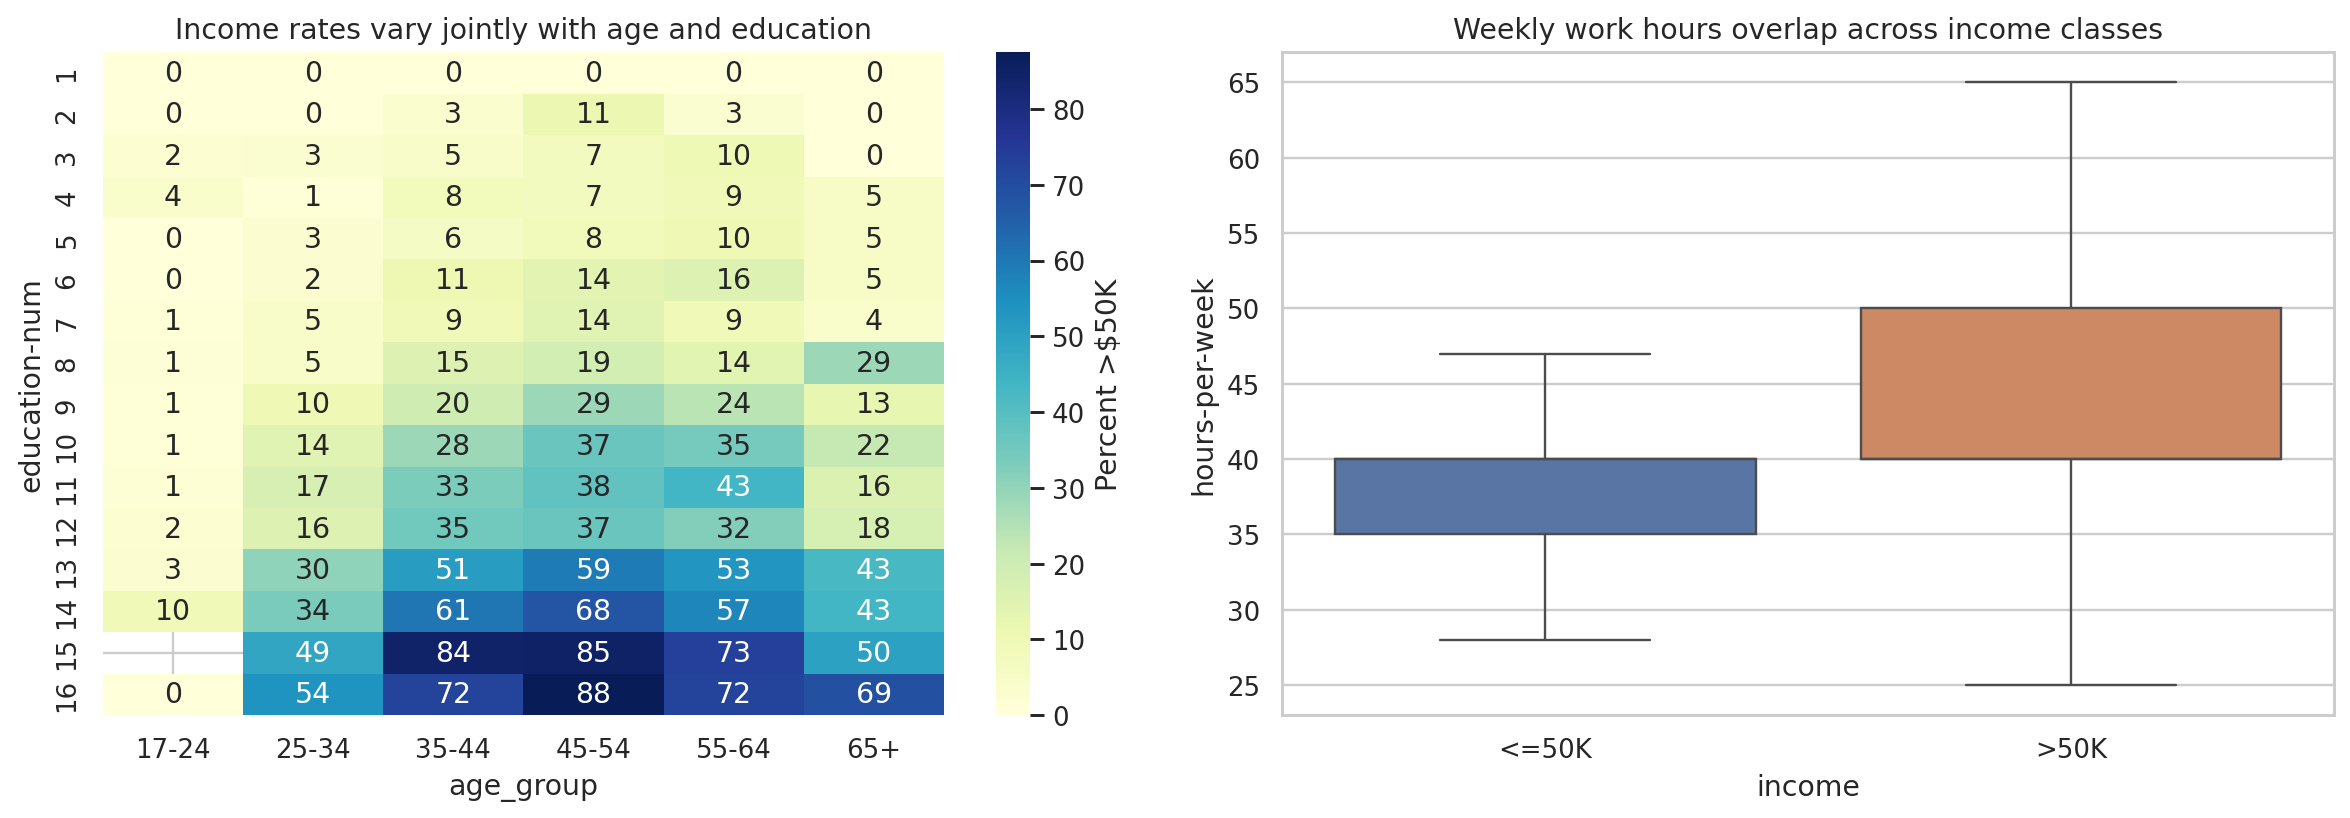

In [3]:
# Interaction-focused exploration retained from professor feedback.
clean['age_group']=pd.cut(clean.age,bins=np.array([16,25,35,45,55,65,91]),labels=['17-24','25-34','35-44','45-54','55-64','65+'],right=False,include_lowest=True)
interaction=clean.pivot_table(index='education-num',columns='age_group',values='income_binary',aggfunc='mean',observed=True)*100
fig,axes=plt.subplots(1,2,figsize=(14,5))
sns.heatmap(interaction,cmap='YlGnBu',annot=True,fmt='.0f',cbar_kws={'label':'Percent >$50K'},ax=axes[0]); axes[0].set_title('Income rates vary jointly with age and education')
sns.boxplot(data=clean,x='income',y='hours-per-week',hue='income',legend=False,showfliers=False,ax=axes[1]); axes[1].set_title('Weekly work hours overlap across income classes')
plt.tight_layout(); plt.savefig(FIGURE_DIR/'eda_interactions.png',dpi=170,bbox_inches='tight'); plt.show()

In [4]:
numeric=['age','fnlwgt','education-num','capital-gain','capital-loss','hours-per-week']
categorical=['workclass','marital-status','occupation','relationship','race','sex','native-country']
X=clean[numeric+categorical].copy(); y=clean.income_binary.to_numpy()
X_train_full,X_test,y_train_full,y_test=train_test_split(X,y,test_size=.15,random_state=RANDOM_STATE,stratify=y)
X_train,X_val,y_train,y_val=train_test_split(X_train_full,y_train_full,test_size=.17647,random_state=RANDOM_STATE,stratify=y_train_full)
preprocessor=ColumnTransformer([
 ('num',Pipeline([('imputer',SimpleImputer(strategy='median')),('scaler',StandardScaler())]),numeric),
 ('cat',Pipeline([('imputer',SimpleImputer(strategy='most_frequent')),('onehot',OneHotEncoder(handle_unknown='ignore',min_frequency=10,sparse_output=False))]),categorical)
])
X_train_p=preprocessor.fit_transform(X_train).astype('float32')
X_val_p=preprocessor.transform(X_val).astype('float32'); X_test_p=preprocessor.transform(X_test).astype('float32')
feature_count=X_train_p.shape[1]
split=pd.DataFrame({'records':[len(X_train),len(X_val),len(X_test)],'percent_above_50K':[y_train.mean()*100,y_val.mean()*100,y_test.mean()*100]},index=['Training','Validation','Test'])
print('Encoded feature count:',feature_count); split.round(2)

Encoded feature count: 89
Out[0]: 
            records  percent_above_50K
Training      22775              24.09
Validation     4881              24.09
Test           4881              24.09


## Step 3: Analyze data

Four approaches are compared on the same untouched test partition:

- Majority baseline: predicts the most common class.
- Logistic regression: conventional linear classification benchmark.
- Dense MLP: two nonlinear hidden layers with dropout and L2 regularization.
- LSTM: treats the encoded feature vector as an artificial sequence, solely to demonstrate recurrent-model implementation.

Class weights reduce the influence of class imbalance. Both neural models use Adam optimization, binary cross-entropy loss, and early stopping.

In [5]:
class_values=np.array([0,1]); weights=compute_class_weight('balanced',classes=class_values,y=y_train); class_weight={0:float(weights[0]),1:float(weights[1])}

def build_mlp():
 model=keras.Sequential([layers.Input(shape=(feature_count,)),layers.Dense(128,activation='relu',kernel_regularizer=regularizers.l2(1e-4)),layers.Dropout(.25),layers.Dense(64,activation='relu'),layers.Dropout(.20),layers.Dense(1,activation='sigmoid')],name='Dense_MLP')
 model.compile(optimizer='adam',loss='binary_crossentropy',metrics=[keras.metrics.AUC(name='auc')]); return model

def build_lstm():
 model=keras.Sequential([layers.Input(shape=(feature_count,1)),layers.LSTM(32,kernel_regularizer=regularizers.l2(1e-4)),layers.Dropout(.20),layers.Dense(1,activation='sigmoid')],name='Feature_Sequence_LSTM')
 model.compile(optimizer='adam',loss='binary_crossentropy',metrics=[keras.metrics.AUC(name='auc')]); return model

early=callbacks.EarlyStopping(monitor='val_auc',mode='max',patience=8,min_delta=.001,restore_best_weights=True)
mlp=build_mlp(); t=time.perf_counter(); hist_mlp=mlp.fit(X_train_p,y_train,validation_data=(X_val_p,y_val),epochs=60,batch_size=128,class_weight=class_weight,callbacks=[early],verbose=0); mlp_time=time.perf_counter()-t
X_train_seq=X_train_p[...,None]; X_val_seq=X_val_p[...,None]; X_test_seq=X_test_p[...,None]
lstm=build_lstm(); tf.keras.utils.set_random_seed(RANDOM_STATE); t=time.perf_counter(); hist_lstm=lstm.fit(X_train_seq,y_train,validation_data=(X_val_seq,y_val),epochs=40,batch_size=128,class_weight=class_weight,callbacks=[early],verbose=0); lstm_time=time.perf_counter()-t
print(f'MLP epochs: {len(hist_mlp.history["loss"])}; seconds: {mlp_time:.2f}')
print(f'LSTM epochs: {len(hist_lstm.history["loss"])}; seconds: {lstm_time:.2f}')

MLP epochs: 14; seconds: 17.26
LSTM epochs: 40; seconds: 277.98


In [6]:
logistic=LogisticRegression(max_iter=1500,C=.1,class_weight='balanced',solver='liblinear',random_state=RANDOM_STATE).fit(X_train_p,y_train)
scores={'Majority baseline':np.repeat(y_train.mean(),len(y_test)),'Logistic regression':logistic.predict_proba(X_test_p)[:,1],'Dense MLP':mlp.predict(X_test_p,verbose=0).ravel(),'Feature-sequence LSTM':lstm.predict(X_test_seq,verbose=0).ravel()}

def row(name,score):
 pred=(score>=.5).astype(int) if name!='Majority baseline' else np.zeros(len(score),dtype=int)
 return {'model':name,'accuracy':accuracy_score(y_test,pred),'precision':precision_score(y_test,pred,zero_division=0),'recall':recall_score(y_test,pred,zero_division=0),'f1':f1_score(y_test,pred,zero_division=0),'roc_auc':roc_auc_score(y_test,score)}
results=pd.DataFrame([row(k,v) for k,v in scores.items()]).set_index('model')
results.mul(100).round(2)

Out[0]: 
                       accuracy  precision  recall     f1  roc_auc
model                                                             
Majority baseline         75.91       0.00    0.00   0.00    50.00
Logistic regression       81.09      57.16   85.88  68.64    91.08
Dense MLP                 82.26      58.83   87.84  70.46    91.79
Feature-sequence LSTM     73.47      46.84   75.00  57.67    81.80


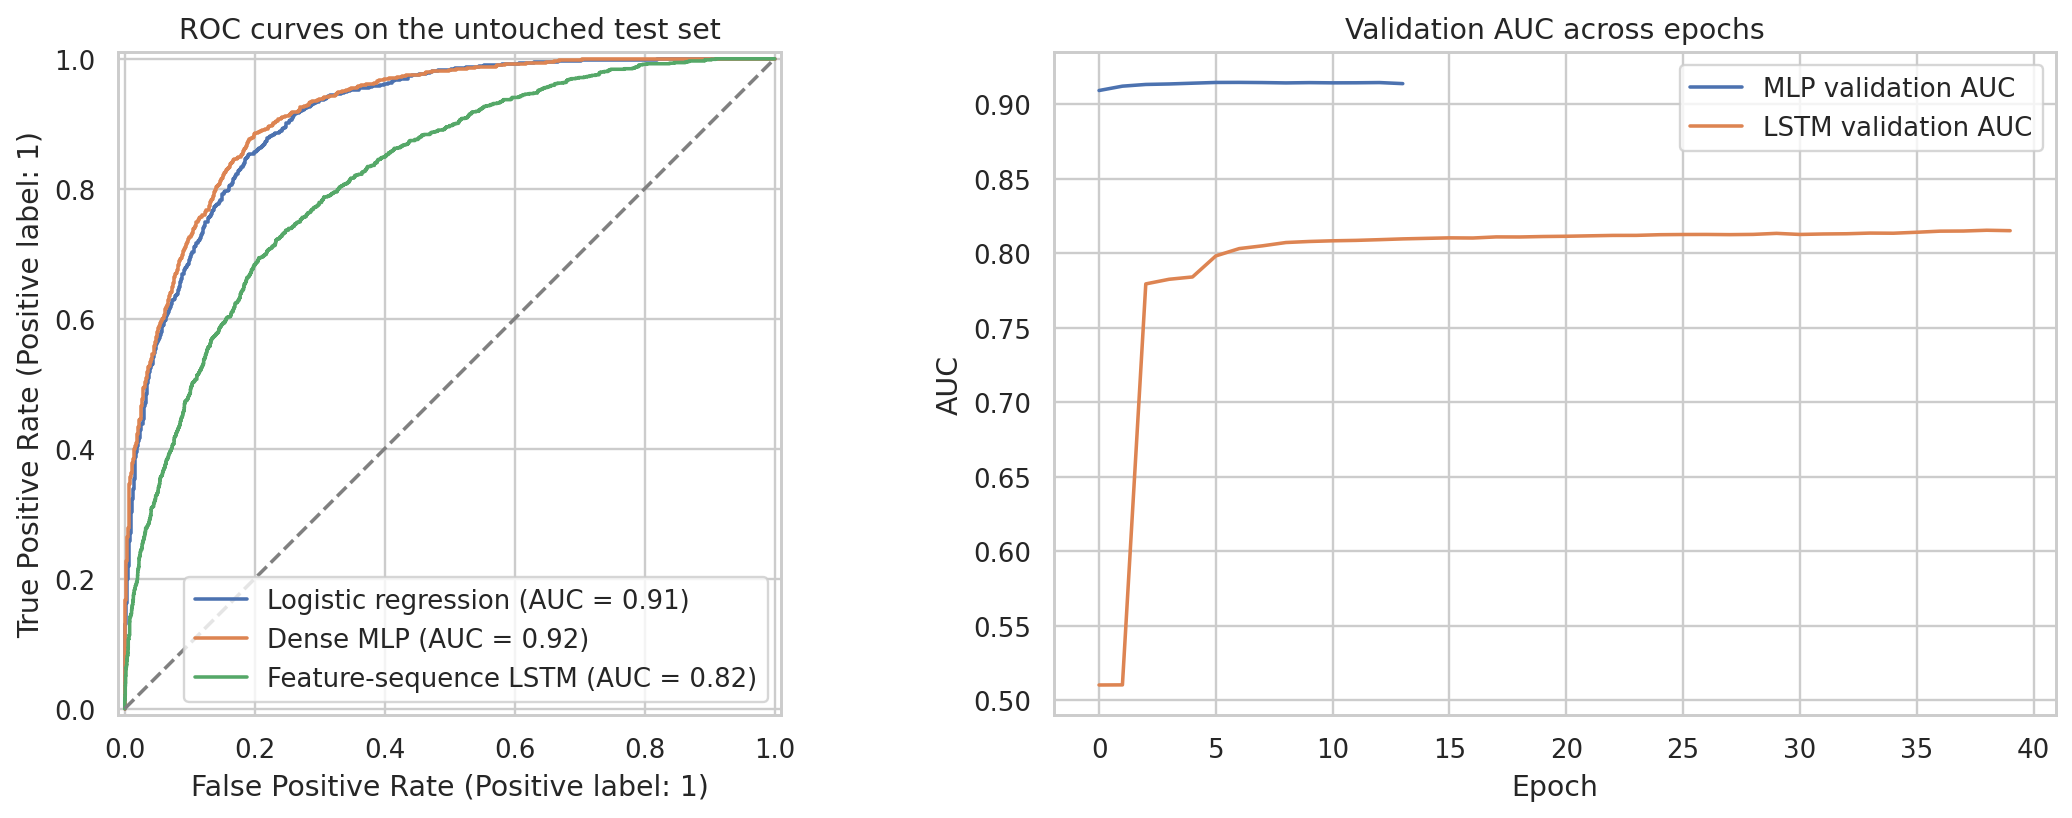

In [7]:
fig,axes=plt.subplots(1,2,figsize=(13,5))
for name in ['Logistic regression','Dense MLP','Feature-sequence LSTM']:
 RocCurveDisplay.from_predictions(y_test,scores[name],name=name,ax=axes[0])
axes[0].plot([0,1],[0,1],'--',color='gray'); axes[0].set_title('ROC curves on the untouched test set')
axes[1].plot(hist_mlp.history['val_auc'],label='MLP validation AUC'); axes[1].plot(hist_lstm.history['val_auc'],label='LSTM validation AUC'); axes[1].set_title('Validation AUC across epochs'); axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('AUC'); axes[1].legend()
plt.tight_layout(); plt.savefig(FIGURE_DIR/'roc_learning.png',dpi=170,bbox_inches='tight'); plt.show()

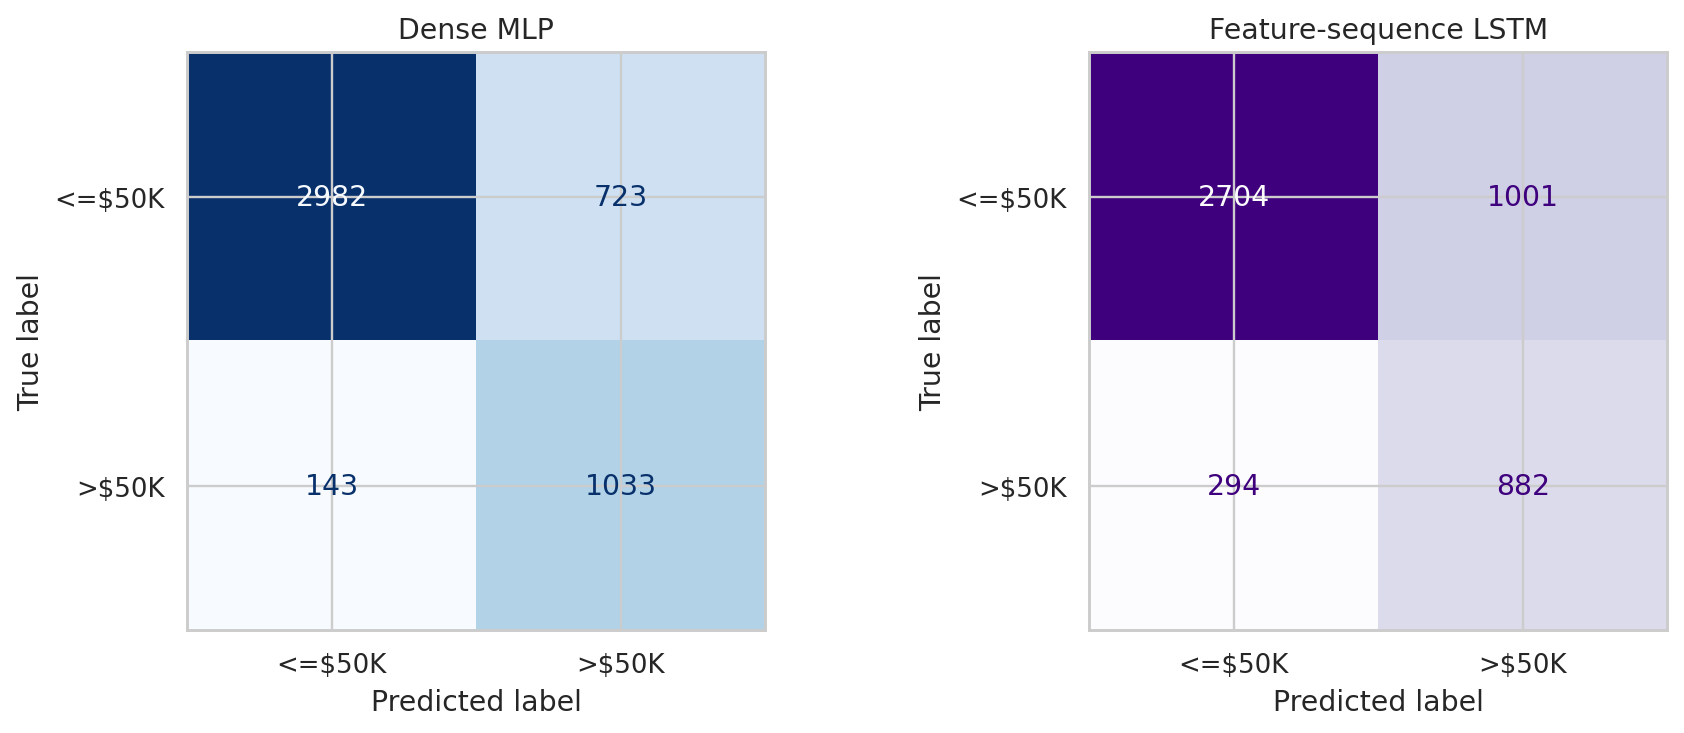

In [8]:
mlp_pred=(scores['Dense MLP']>=.5).astype(int); lstm_pred=(scores['Feature-sequence LSTM']>=.5).astype(int)
fig,axes=plt.subplots(1,2,figsize=(11,4.5))
ConfusionMatrixDisplay.from_predictions(y_test,mlp_pred,display_labels=['<=$50K','>$50K'],cmap='Blues',colorbar=False,ax=axes[0]); axes[0].set_title('Dense MLP')
ConfusionMatrixDisplay.from_predictions(y_test,lstm_pred,display_labels=['<=$50K','>$50K'],cmap='Purples',colorbar=False,ax=axes[1]); axes[1].set_title('Feature-sequence LSTM')
plt.tight_layout(); plt.savefig(FIGURE_DIR/'confusion_matrices.png',dpi=170,bbox_inches='tight'); plt.show()

## Step 4: Report

ROC-AUC evaluates ranking across all thresholds, while precision, recall, and F1 describe positive-class performance at the default threshold. Accuracy remains useful but can appear strong because most records fall in the `<=50K` class.

The model with the strongest balance of ROC-AUC and F1 becomes the recommended analytical benchmark. Any advantage from the LSTM must be interpreted cautiously because its feature order is artificial rather than temporal.

In [9]:
candidate=results.loc[['Dense MLP','Feature-sequence LSTM']]
selected_model=candidate.roc_auc.idxmax()
summary=pd.Series({'selected_model':selected_model,'accuracy_percent':results.loc[selected_model,'accuracy']*100,'precision_percent':results.loc[selected_model,'precision']*100,'recall_percent':results.loc[selected_model,'recall']*100,'f1_percent':results.loc[selected_model,'f1']*100,'roc_auc_percent':results.loc[selected_model,'roc_auc']*100,'baseline_accuracy_percent':results.loc['Majority baseline','accuracy']*100,'test_records':len(y_test),'encoded_features':feature_count})
summary.round(2)

Out[0]: 
selected_model               Dense MLP
accuracy_percent             82.257734
precision_percent            58.826879
recall_percent               87.840136
f1_percent                   70.463847
roc_auc_percent               91.79058
baseline_accuracy_percent    75.906577
test_records                      4881
encoded_features                    89
dtype: object


## Step 5: Act

The selected neural model can serve as an experimental classification benchmark for the historical dataset. A responsible next step would compare calibration, tune the probability threshold for a clearly defined use case, and examine performance across demographic groups.

The model should not make employment, credit, compensation, or eligibility decisions. The source data reflect 1994 conditions, include sensitive attributes, and encode historical social patterns. The LSTM also lacks temporal meaning in this dataset. Current representative data, fairness review, human oversight, and an appeal process would be necessary before consequential use. (OpenAI, 2026)

## Limitations and conclusion

- Adult Income is cross-sectional and does not satisfy a genuine time-series requirement.
- The LSTM sequence order comes from encoded feature positions, not timestamps.
- One test split cannot establish performance in another population or period.
- The binary income threshold discards variation within each income category.
- Predictive associations do not establish causal effects.

The project completes all five data-science steps and demonstrates deep learning with MLP and LSTM architectures. The results should be evaluated as classification results, not recurrent time-series forecasting.

## References

- Becker, B., & Kohavi, R. (1996). *Adult* [Dataset]. UCI Machine Learning Repository. https://archive.ics.uci.edu/dataset/2/adult
- National University. (2026). *ANA500 Module 4: Neural Network Modeling with Python* [Course tutorials].
- OpenAI. (2026). *ChatGPT* [Large language model]. https://chatgpt.com/
- TensorFlow Developers. (2026). *TensorFlow and Keras documentation*. https://www.tensorflow.org/